# Predicting the payment method for a NYC yellow taxi trip

| Section | What it does | Owner |
|---|---|---|
| 0 · Setup | Libraries, settings, which months to use, get and check the data files | Bri |
| 1 · Data cleaning | Label each trip card or cash, clean out bad trips, prepare each month in parallel | Bri |
| 2 · Features | Turn trips into numbers the model can use |Marks |
| 3 · Models | Baseline, model search, final model |Marks|
| 4 · Evaluation | Score the final model on the test months, once | Ilja |

**How to run it.** Run each section in order.

**Laptop vs Rockhill.** On a laptop, Section 0 samples 2% of January to March 2026. On Rockhill it samples 5% of January to September 2026. Data, prepared tables and results are saved under the repository root. Section 0 records the environment and configuration in `results/00_run_info.json`.

## Section 0 · Setup

This section carries out the following:
* Loads all necessary libraries
* Chooses the months from the dataset
* Ensures files are present
* Checks that months have the correct columns
* Describes the raw data

### 0.1 Libraries

In [1]:
# If a library is missing, remove the # on the next line, run this cell once, then restart the kernel
# %pip install pandas pyarrow scikit-learn matplotlib
import urllib.request
import os
for var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(var, "1")

import json
import platform
import shutil
import sys
import time
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from joblib import Parallel, delayed

pd.set_option("display.width", 140)

### 0.2 Shared settings
Settings every section uses. `ON_ROCKHILL` is `True` when the notebook can see Rockhill's shared data folder, which is how it knows where it is running.

In [2]:
#Rockhills location of the dataset
SHARED_DATA = Path("/home/cs4207/data")
ON_ROCKHILL = SHARED_DATA.exists()

working_dir = Path.cwd().resolve()
REPO_ROOT = next(
    (
        folder
        for folder in (working_dir, *working_dir.parents)
        if (folder / "notebooks" / "taxipay_pipeline.ipynb").is_file()
        and (folder / "requirements.txt").is_file()
    ),
    None,
)
if REPO_ROOT is None:
    raise RuntimeError("Start the notebook from inside the project folder.")

DATA_DIR = REPO_ROOT / "data"
PREPARED_DIR = REPO_ROOT / "prepared"
RESULTS_DIR = REPO_ROOT / "results"
TLC_URL = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_{year}-{month:02d}.parquet"

#Fixed seed so every run gives the same sampple
SEED = 4207
MAX_WORKERS = 3

#Labels and codes for prediction
CARD, CASH = 1, 2
LABEL = "is_cash"

#Remove leakage
LEAKY_COLUMNS = ["tip_amount", "total_amount", "payment_type"]

for folder in (DATA_DIR, PREPARED_DIR, RESULTS_DIR):
    folder.mkdir(exist_ok=True)
print("Running on", "Rockhill" if ON_ROCKHILL else "a laptop")

Running on a laptop


### 0.3 Input: which data to use
**Months are written `YYYY-MM`.**

Splits the data into train, val and test. 

In [3]:
if ON_ROCKHILL:
    TRAIN = ["2026-01", "2026-02", "2026-03", "2026-04", "2026-05", "2026-06"]
    VAL   = ["2026-07"]
    TEST  = ["2026-08", "2026-09"]
    SAMPLE_FRACTION = 0.05
#On laptop, we download 3 months for testing purposes
else:
    TRAIN = ["2026-01"]
    VAL   = ["2026-02"]
    TEST  = ["2026-03"]
    SAMPLE_FRACTION = 0.02
DOWNLOAD_MISSING = True

#Prints information of split
def parse_month(text):
    """'2026-01' -> (2026, 1)"""
    year, month = text.split("-")
    return int(year), int(month)

SPLITS = {"train": [parse_month(m) for m in TRAIN],
          "val":   [parse_month(m) for m in VAL],
          "test":  [parse_month(m) for m in TEST]}
ALL_MONTHS = [ym for months in SPLITS.values() for ym in months]

assert all(SPLITS.values()), "every split needs at least one month"
assert len(ALL_MONTHS) == len(set(ALL_MONTHS)), \
    "a month is in more than one split: that leaks test data into training"
assert 0 < SAMPLE_FRACTION <= 1, "SAMPLE_FRACTION must be between 0 and 1"

for split, months in SPLITS.items():
    print(f"{split:5s} {', '.join(f'{y}-{m:02d}' for y, m in months)}")
print(f"keeping {SAMPLE_FRACTION:.0%} of each month's trips")

packages = [
    "numpy", "pandas", "pyarrow", "scikit-learn",
    "joblib", "matplotlib", "ipykernel", "nbconvert",
]

run_info = {
    "python": sys.version,
    "platform": platform.platform(),
    "machine": platform.machine(),
    "logical_cpus": os.cpu_count(),
    "slurm_cpus_per_task": os.environ.get("SLURM_CPUS_PER_TASK"),
    "slurm_cpus_on_node": os.environ.get("SLURM_CPUS_ON_NODE"),
    "packages": {name: version(name) for name in packages},
    "on_rockhill": ON_ROCKHILL,
    "train_months": TRAIN,
    "validation_months": VAL,
    "test_months": TEST,
    "sample_fraction": SAMPLE_FRACTION,
    "seed": SEED,
    "max_workers": MAX_WORKERS,
    "thread_limits": {
        name: os.environ.get(name)
        for name in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS")
    },
}

print(json.dumps(run_info, indent=2))
(RESULTS_DIR / "00_run_info.json").write_text(
    json.dumps(run_info, indent=2), encoding="utf-8"
)

train 2026-01
val   2026-02
test  2026-03
keeping 2% of each month's trips
{
  "python": "3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]",
  "platform": "Windows-11-10.0.26200-SP0",
  "machine": "AMD64",
  "logical_cpus": 22,
  "slurm_cpus_per_task": null,
  "slurm_cpus_on_node": null,
  "packages": {
    "numpy": "2.5.5",
    "pandas": "3.1.1",
    "pyarrow": "26.0.1",
    "scikit-learn": "1.9.1",
    "joblib": "1.6.0",
    "matplotlib": "3.11.2",
    "ipykernel": "7.4.0",
    "nbconvert": "7.17.2"
  },
  "on_rockhill": false,
  "train_months": [
    "2026-01"
  ],
  "validation_months": [
    "2026-02"
  ],
  "test_months": [
    "2026-03"
  ],
  "sample_fraction": 0.02,
  "seed": 4207,
  "max_workers": 3,
  "thread_limits": {
    "OMP_NUM_THREADS": "1",
    "OPENBLAS_NUM_THREADS": "1",
    "MKL_NUM_THREADS": "1"
  }
}


793

### 0.4 Get the files
For each month, it finds where its data is stored. If there are any months missing, it downloads them from the TLC website. 

In [4]:
#Finds where a months file is
def month_file(year, month):
    name = f"yellow_tripdata_{year}-{month:02d}.parquet"
    for folder in (SHARED_DATA, DATA_DIR, REPO_ROOT / "notebooks" / "data"):
        if (folder / name).exists():
            return folder / name
    return DATA_DIR / name

#This downloads a months dataset from the TLC website
#Only using this for testing purposes on laptop, to be removed
def download(year, month, dest):
    url = TLC_URL.format(year=year, month=month)
    tmp = dest.with_suffix(".part")
    try:
        with urllib.request.urlopen(url, timeout=60) as response, open(tmp, "wb") as out:
            shutil.copyfileobj(response, out)
        tmp.rename(dest)
    except Exception as err:
        tmp.unlink(missing_ok=True)
        raise RuntimeError(f"Could not download {url} ({err}). Download it in a browser "
                           f"from the TLC page and save it as {dest}") from err

#Loops through every file and records info such as data source, its size and the amount of trips inside it
files = []
for split, months in SPLITS.items():
    for year, month in months:
        path = month_file(year, month)
        source = "Rockhill shared folder" if path.parent == SHARED_DATA else str(path.parent.relative_to(REPO_ROOT))
        if not path.exists():
            if not DOWNLOAD_MISSING:
                raise FileNotFoundError(f"{path.name} is missing: set DOWNLOAD_MISSING = True")
            print(f"Downloading {path.name} ...", flush=True)
            download(year, month, path)
            source = "downloaded now"
        files.append({"split": split, "month": f"{year}-{month:02d}", "source": source,
                      "MB": round(path.stat().st_size / 1e6, 1),
                      "trips": pq.ParquetFile(path).metadata.num_rows, "path": path})
files = pd.DataFrame(files)

files.drop(columns="path").to_csv(RESULTS_DIR / "00_input_files.csv", index=False)
print(files.drop(columns="path").to_string(index=False))
print(f"\nTotal: {files['trips'].sum():,} trips in {len(files)} files, {files['MB'].sum():,.0f} MB")

split   month         source   MB   trips
train 2026-01 notebooks\data 64.2 3724889
  val 2026-02 notebooks\data 58.7 3399866
 test 2026-03 notebooks\data 67.9 3952451

Total: 11,077,206 trips in 3 files, 191 MB


### 0.5 Do the months have the same columns?

In [5]:
#The columns that each month should have
REQUIRED = ["tpep_pickup_datetime", "tpep_dropoff_datetime", "payment_type", "fare_amount",
            "trip_distance", "PULocationID", "DOLocationID"]

#Creats a dictionary of each months columns and column types
columns = pd.DataFrame({f["month"]: {c.name.lower(): str(c.type) for c in pq.read_schema(f["path"])}
                        for _, f in files.iterrows()})

#Ensures no month has a missing column
missing = [c for c in REQUIRED if c.lower() not in columns.index or columns.loc[c.lower()].isna().any()]
assert not missing, f"some months are missing required columns: {missing}"

#Ensures no columns differ from other months
differs = columns[columns.nunique(axis=1, dropna=False) > 1]
print(f"{len(columns)} columns; every required one is in every month")
if differs.empty:
    print("Every month has the same columns and types")
else:
    print("Columns that differ between months (blank = that month doesn't have it):")
    print(differs.fillna("").to_string())

20 columns; every required one is in every month
Every month has the same columns and types


### 0.6 Raw data visualisation

In [6]:
#Maps each code to its payment type
PAYMENT_NAMES = {0: "Flex Fare", 1: "Credit card", 2: "Cash", 3: "No charge",
                 4: "Dispute", 5: "Unknown", 6: "Voided"}

#Reads through the first 200,000 trips
first_file = pq.ParquetFile(files["path"].iloc[0])
raw = next(first_file.iter_batches(batch_size=200_000)).to_pandas()
print(f"First {len(raw):,} trips of {files['month'].iloc[0]}, all {raw.shape[1]} columns\n")

print("How trips were paid:")
print(raw["payment_type"].map(PAYMENT_NAMES).value_counts(normalize=True).round(3).to_string())
share_missing = raw.isna().mean()
print("\nShare of missing values:")
print(share_missing[share_missing > 0].round(3).to_string())
raw.head()

First 200,000 trips of 2026-01, all 20 columns

How trips were paid:
payment_type
Credit card    0.800
Cash           0.164
Dispute        0.028
No charge      0.008

Share of missing values:
Series([], )


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,2,2026-01-01 00:54:04,2026-01-01 00:59:37,1,0.97,1,N,239,238,1,7.2,1.00,0.5,3.66,0.0,1.0,15.86,2.5,0.0,0.00
1,1,2026-01-01 00:34:04,2026-01-01 00:39:47,0,0.90,1,N,163,162,2,7.9,4.25,0.5,0.00,0.0,1.0,13.65,2.5,0.0,0.75
2,1,2026-01-01 00:57:06,2026-01-01 01:05:59,0,1.40,1,N,43,237,1,10.7,4.25,0.5,2.50,0.0,1.0,18.95,2.5,0.0,0.75
3,2,2026-01-01 00:15:22,2026-01-01 00:58:10,4,5.58,1,N,142,209,1,38.7,1.00,0.5,11.11,0.0,1.0,55.56,2.5,0.0,0.75
4,2,2026-01-01 00:27:13,2026-01-01 00:40:43,0,2.16,1,N,88,144,1,13.5,1.00,0.5,3.85,0.0,1.0,23.10,2.5,0.0,0.75


In [7]:
raw.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
VendorID,200000.0,1.886255,1.0,2.0,2.0,2.0,7.0,0.768479
tpep_pickup_datetime,200000,2026-01-02 12:20:08.537485,2025-12-31 23:57:29,2026-01-01 17:52:43,2026-01-02 14:53:45,2026-01-03 06:48:01,2026-01-03 19:11:44,NaN
tpep_dropoff_datetime,200000,2026-01-02 12:35:38.545325,2025-12-31 23:57:32,2026-01-01 18:08:00,2026-01-02 15:11:03,2026-01-03 07:05:28,2026-01-05 20:44:12,NaN
passenger_count,200000.0,1.46401,0.0,1.0,1.0,2.0,6.0,0.872008
trip_distance,200000.0,3.935557,0.0,0.99,1.74,3.77,36610.27,82.008964
RatecodeID,200000.0,3.923745,1.0,1.0,1.0,1.0,99.0,16.249721
PULocationID,200000.0,161.655985,1.0,132.0,161.0,230.0,265.0,63.743393
DOLocationID,200000.0,161.27757,1.0,107.0,161.0,233.0,265.0,70.59746
payment_type,200000.0,1.264585,1.0,1.0,1.0,1.0,4.0,0.616061
fare_amount,200000.0,19.944072,-629.5,8.6,12.8,23.3,850.0,22.100838


## Section 1 · Data cleaning

Keeps card and cash trips, adds the label for each, removes trips that can't be real, and saves one cleaned file per month in `prepared/`.

The months are prepared in parallel, one month per worker process. This is the **data parallelism** for this section.

Saves: `prepared/YYYY-MM.parquet`, `results/01_cleaning_rules.csv`, `results/01_prepare_stats.csv`, `results/01_timings.json`, `results/01_cash_share.png`

### 1.1 Leakage
`payment_type` has seven codes. We keep 1 (card) and 2 (cash), and our model predicts cash.

The TLC records tips automatically for card payments, and cash tips aren't recorded. So a tip above zero almost always means card, and `total_amount` includes the tip. The below table shows this, which is why we won't use these as a feature moving forward. 

In [8]:
#Groups trips by their payment type and records how many of these payments have tips
summary = (raw.groupby("payment_type")
              .agg(trips=("fare_amount", "size"),
                   share_with_tip=("tip_amount", lambda tips: (tips > 0).mean()))
              .rename(index=PAYMENT_NAMES))
summary["share_of_trips"] = summary["trips"] / summary["trips"].sum()
print(summary.round(3).to_string())

               trips  share_with_tip  share_of_trips
payment_type                                        
Credit card   159961           0.902           0.800
Cash           32778           0.000           0.164
No charge       1644           0.000           0.008
Dispute         5617           0.000           0.028


### 1.2 Cleaning rules
A trip is kept only if it passes every rule:

| Rule | Why |
|---|---|
| paid by card or cash | the two classes we predict |
| picked up in the file's own month | some files contain a few trips with wrong dates|
| fare between \$3 and \$500 | negative fares are refunds; the meter minimum is about \$3 |
| distance between 0.1 and 100 miles | 0 miles is a meter error |
| duration between 1 and 180 minutes | shorter is a cancelled trip, longer a meter left running |

In [9]:
PICKUP, DROPOFF = "tpep_pickup_datetime", "tpep_dropoff_datetime"

# The columns we use. tip_amount and total_amount are left out.
KEEP_COLUMNS = ["VendorID", PICKUP, DROPOFF, "passenger_count", "trip_distance",
                "RatecodeID", "store_and_fwd_flag", "PULocationID", "DOLocationID",
                "payment_type", "fare_amount", "extra", "mta_tax", "tolls_amount",
                "improvement_surcharge", "congestion_surcharge", "airport_fee",
                "cbd_congestion_fee"]


def read_month(path, columns=KEEP_COLUMNS):
    actual = {name.lower(): name for name in pq.read_schema(path).names}
    present = [c for c in columns if c.lower() in actual]
    df = pd.read_parquet(path, columns=[actual[c.lower()] for c in present])
    df.columns = present
    for c in columns:
        if c not in df:
            df[c] = 0.0
    return df[columns]


def cleaning_rules(df, year, month):
    minutes = (df[DROPOFF] - df[PICKUP]).dt.total_seconds() / 60
    return pd.DataFrame({
        "card_or_cash": df["payment_type"].isin([CARD, CASH]),
        "in_month": (df[PICKUP].dt.year == year) & (df[PICKUP].dt.month == month),
        "fare_3_to_500": df["fare_amount"].between(3, 500),
        "distance_0.1_to_100": df["trip_distance"].between(0.1, 100),
        "duration_1_to_180": minutes.between(1, 180),
    })

### 1.3 Prepare every month: Uses either one process or several
`prepare_month` prepares one month. It is run once per month, first one month after another, then with up to `MAX_WORKERS` months at the same time in separate worker processes, and the two times are compared.

In [10]:
#This prepares each month by reading it, creating a sample, cleaning, labelling and saving
def prepare_month(year, month, path, sample_fraction, seed, out_dir):
    start = time.perf_counter()
    df = read_month(path)
    raw_trips = len(df)
    # fixed random sample: the same rows every run (the seed differs per month)
    df = df.sample(frac=sample_fraction, random_state=seed + year * 100 + month)
    rules = cleaning_rules(df, year, month)
    df = df[rules.all(axis=1)].copy()
    df[LABEL] = (df["payment_type"] == CASH).astype("int8")
    df = df.drop(columns="payment_type").sort_values(PICKUP, kind="stable").reset_index(drop=True)
    df.to_parquet(Path(out_dir) / f"{year}-{month:02d}.parquet", index=False)
    return {"month": f"{year}-{month:02d}", "raw_trips": raw_trips, "sampled": len(rules),
            "kept": len(df), "cash_share": round(float(df[LABEL].mean()), 4),
            "seconds": round(time.perf_counter() - start, 2)}

#Prepares every month using n workers
def prepare_all(n_workers):
    jobs = [delayed(prepare_month)(y, m, month_file(y, m), SAMPLE_FRACTION, SEED, PREPARED_DIR)
            for y, m in ALL_MONTHS]
    return pd.DataFrame(Parallel(n_jobs=n_workers)(jobs))


RUN_SEQUENTIAL = True
timings = {"months": len(ALL_MONTHS), "workers": min(MAX_WORKERS, len(ALL_MONTHS)),
           "sample_fraction": SAMPLE_FRACTION}
if RUN_SEQUENTIAL:
    start = time.perf_counter()
    prepare_all(n_workers=1)
    timings["sequential_s"] = round(time.perf_counter() - start, 2)

start = time.perf_counter()
stats = prepare_all(n_workers=timings["workers"])
timings["parallel_s"] = round(time.perf_counter() - start, 2)
if RUN_SEQUENTIAL:
    timings["speedup"] = round(timings["sequential_s"] / timings["parallel_s"], 2)

stats.to_csv(RESULTS_DIR / "01_prepare_stats.csv", index=False)
(RESULTS_DIR / "01_timings.json").write_text(json.dumps(timings, indent=2))
print(timings)
stats

{'months': 3, 'workers': 3, 'sample_fraction': 0.02, 'sequential_s': 3.97, 'parallel_s': 3.08, 'speedup': 1.29}


,month,raw_trips,sampled,kept,cash_share,seconds
0,2026-01,3724889,74498,49406,0.1158,1.61
1,2026-02,3399866,67997,44888,0.1141,1.50
2,2026-03,3952451,79049,57229,0.1154,1.77


### 1.4 Prepare cleaned data for later sections
`load_split("train")`, `load_split("val")` and `load_split("test")` return all the cleaned trips of a split as one table, with the label in the `is_cash` column.

In [11]:
def load_split(name):
    paths = [PREPARED_DIR / f"{y}-{m:02d}.parquet" for y, m in SPLITS[name]]
    missing = [p.name for p in paths if not p.exists()]
    if missing:
        raise FileNotFoundError(f"{missing} not prepared yet: run Section 1 first")
    return pd.concat([pd.read_parquet(p) for p in paths], ignore_index=True)


train = load_split("train")
print(f"train: {len(train):,} trips, {train.shape[1]} columns, cash share {train[LABEL].mean():.3f}")
print("columns:", ", ".join(train.columns))

train: 49,406 trips, 18 columns, cash share 0.116
columns: VendorID, tpep_pickup_datetime, tpep_dropoff_datetime, passenger_count, trip_distance, RatecodeID, store_and_fwd_flag, PULocationID, DOLocationID, fare_amount, extra, mta_tax, tolls_amount, improvement_surcharge, congestion_surcharge, airport_fee, cbd_congestion_fee, is_cash


## Section 2 · Features

Turns each cleaned trip into numbers the model can use. Uses the train and val splits only; the test split is not touched until Section 4.

This section carries out the following:
* Adds new columns worked out from each trip on its own (time of day, duration, speed, ...)
* Looks at how the cash share changes with some of them, using train only
* Builds the preprocessing step, which is fitted on train only inside each model in Section 3
* Saves the feature tables so the Section 3 workers can read them

Saves: `prepared/features_train.parquet`, `prepared/features_val.parquet`, `results/02_feature_list.csv`, `results/02_cash_by_feature.png`, `results/02_cash_by_zone.csv`

### 2.1 The features

| Feature | Worked out from | Why it could help |
|---|---|---|
| `hour`, `day_of_week`, `is_weekend`, `is_night` | pickup time | late night and weekend trips may be paid differently |
| `duration_min`, `speed_mph` | pickup and dropoff times, distance | short, slow trips are typical of cash |
| `fare_per_mile` | fare and distance | separates flat rates and heavy traffic |
| `has_tolls`, `is_airport` | tolls, airport fee, rate code, zone | airport and toll trips are longer and more often paid by card |
| `same_zone` | pickup and dropoff zones | very local trips |
| `trip_distance`, `fare_amount`, `extra`, `tolls_amount`, `congestion_surcharge`, `airport_fee`, `cbd_congestion_fee`, `passenger_count`, `store_and_fwd` | as recorded | the trip itself |
| `VendorID`, `RatecodeID` | as recorded | categories, one-hot encoded |
| `PULocationID`, `DOLocationID`, `route` | zones (`route` is the pickup-dropoff pair) | cash use differs a lot between areas; target-encoded |

Every feature is worked out from a single trip, so adding them can't leak anything from one split into another. `tip_amount`, `total_amount` and `payment_type` are never used (the check at the end of 2.2 makes sure).

In [12]:
#Zones of the three airports: Newark (1), JFK (132), LaGuardia (138)
AIRPORT_ZONES = [1, 132, 138]


from concurrent.futures import ThreadPoolExecutor


def time_and_speed(df):
    out = pd.DataFrame(index=df.index)
    pickup = df[PICKUP]
    out["hour"] = pickup.dt.hour.astype("int8")
    out["day_of_week"] = pickup.dt.dayofweek.astype("int8")
    out["is_weekend"] = (out["day_of_week"] >= 5).astype("int8")
    out["is_night"] = ((out["hour"] >= 22) | (out["hour"] < 5)).astype("int8")

    #Cleaning keeps trips of at least 1 minute and 0.1 miles, so there is no division by zero
    out["duration_min"] = (df[DROPOFF] - pickup).dt.total_seconds() / 60
    out["speed_mph"] = df["trip_distance"] / (out["duration_min"] / 60)
    out["fare_per_mile"] = df["fare_amount"] / df["trip_distance"]
    return out


def trip_flags(df):
    out = pd.DataFrame(index=df.index)
    out["has_tolls"] = (df["tolls_amount"] > 0).astype("int8")
    out["is_airport"] = ((df["airport_fee"] > 0) | df["RatecodeID"].isin([2, 3])
                         | df["PULocationID"].isin(AIRPORT_ZONES)
                         | df["DOLocationID"].isin(AIRPORT_ZONES)).astype("int8")
    out["same_zone"] = (df["PULocationID"] == df["DOLocationID"]).astype("int8")
    return out


def recorded_features(df):
    out = pd.DataFrame(index=df.index)
    for c in ["trip_distance", "fare_amount", "extra", "tolls_amount", "congestion_surcharge",
              "airport_fee", "cbd_congestion_fee", "passenger_count"]:
        out[c] = df[c].fillna(0).astype("float32")
    out["store_and_fwd"] = (df["store_and_fwd_flag"] == "Y").astype("int8")

    #Categories: missing codes become -1 so they are their own category
    out["VendorID"] = df["VendorID"].fillna(-1).astype("int32")
    out["RatecodeID"] = df["RatecodeID"].fillna(-1).astype("int32")
    out["PULocationID"] = df["PULocationID"].astype("int32")
    out["DOLocationID"] = df["DOLocationID"].astype("int32")
    out["route"] = (out["PULocationID"] * 1000 + out["DOLocationID"]).astype("int32")

    out[LABEL] = df[LABEL].astype("int8")
    return out


def add_features(df, workers=MAX_WORKERS):
    tasks = [time_and_speed, trip_flags, recorded_features]
    if workers == 1:
        blocks = [task(df) for task in tasks]
    else:
        with ThreadPoolExecutor(max_workers=workers) as pool:
            jobs = [pool.submit(task, df) for task in tasks]
            blocks = [job.result() for job in jobs]
    return pd.concat(blocks, axis=1)


#The columns the models see, grouped by how they are encoded
NUMERIC = ["hour", "duration_min", "speed_mph", "fare_per_mile", "trip_distance", "fare_amount",
           "extra", "tolls_amount", "congestion_surcharge", "airport_fee", "cbd_congestion_fee",
           "passenger_count", "is_weekend", "is_night", "has_tolls", "is_airport", "same_zone",
           "store_and_fwd"]
ONE_HOT = ["VendorID", "RatecodeID", "day_of_week"]
TARGET_ENCODED = ["PULocationID", "DOLocationID", "route"]
FEATURES = NUMERIC + ONE_HOT + TARGET_ENCODED

#Leakage check: none of the columns that give away the answer are features
assert not set(FEATURES) & set(LEAKY_COLUMNS + [LABEL]), "a leaky column is in FEATURES"

#Builds the feature tables for train and val and saves them for the Section 3 workers
feature_tables = {}
for split in ("train", "val"):
    feature_tables[split] = add_features(load_split(split))
    feature_tables[split].to_parquet(PREPARED_DIR / f"features_{split}.parquet", index=False)
    print(f"{split:5s} {len(feature_tables[split]):,} trips, {len(FEATURES)} features, "
          f"cash share {feature_tables[split][LABEL].mean():.3f}")

feat_train = feature_tables["train"]
pd.DataFrame({"feature": FEATURES,
              "encoding": ["numeric"] * len(NUMERIC) + ["one-hot"] * len(ONE_HOT)
                          + ["target"] * len(TARGET_ENCODED)}
             ).to_csv(RESULTS_DIR / "02_feature_list.csv", index=False)
feat_train[FEATURES].describe().T.round(2)

train 49,406 trips, 24 features, cash share 0.116


C:\Users\franc\AppData\Local\Temp\ipykernel_16804\2287074843.py:12: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  out["day_of_week"] = pickup.dt.dayofweek.astype("int8")
C:\Users\franc\AppData\Local\Temp\ipykernel_16804\2287074843.py:12: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  out["day_of_week"] = pickup.dt.dayofweek.astype("int8")


val   44,888 trips, 24 features, cash share 0.114


,count,mean,std,min,25%,50%,75%,max
hour,49406.0,14.36,5.52,0.00,11.00,15.00,19.00,23.00
duration_min,49406.0,16.92,15.04,1.00,7.55,12.42,20.57,179.38
speed_mph,49406.0,10.81,6.62,0.22,6.81,9.06,12.41,192.77
fare_per_mile,49406.0,8.31,7.57,0.36,5.80,7.46,9.52,700.00
trip_distance,49406.0,3.43,4.58,0.10,1.00,1.67,3.26,77.37
fare_amount,49406.0,19.31,17.88,3.00,8.60,12.80,21.50,316.60
extra,49406.0,1.49,1.84,0.00,0.00,1.00,2.50,12.50
tolls_amount,49406.0,0.57,2.20,0.00,0.00,0.00,0.00,35.71
congestion_surcharge,49406.0,2.23,0.77,0.00,2.50,2.50,2.50,2.50
airport_fee,49406.0,0.15,0.49,0.00,0.00,0.00,0.00,1.75


### Timing the three feature tasks

Each task reads the same cleaned trips and creates its own columns. We join the blocks in submission order. We time the complete feature step on the training split, including thread setup and the join. Each configuration has a warm-up and three timed runs. Checking the output is outside the timer. Only three tasks are available, and the task that takes longest limits speedup.

C:\Users\franc\AppData\Local\Temp\ipykernel_16804\2287074843.py:12: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  out["day_of_week"] = pickup.dt.dayofweek.astype("int8")
C:\Users\franc\AppData\Local\Temp\ipykernel_16804\2287074843.py:12: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  out["day_of_week"] = pickup.dt.dayofweek.astype("int8")
C:\Users\franc\AppData\Local\Temp\ipykernel_16804\2287074843.py:12: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  out["day_of_week"] = pickup.dt.dayofweek.astype("int8")
C:\Users\franc\AppData\Local\Temp\ipykernel_16804\2287074843.py:12: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  out["day_of_week"] = pickup.dt.dayofweek.astype(

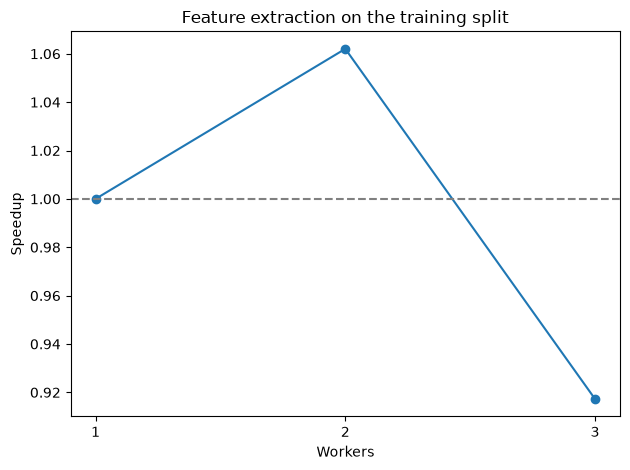

,seconds,speedup,efficiency
workers,,,
1,0.020,1.000,1.000
2,0.019,1.062,0.531
3,0.022,0.917,0.306


In [13]:
reference = add_features(train, workers=1)
worker_counts = list(range(1, min(MAX_WORKERS, 3) + 1))
for workers in worker_counts:
    pd.testing.assert_frame_equal(add_features(train, workers), reference, check_exact=True)

runs = []
for repeat in range(3):
    # Rotate which configuration runs first
    order = worker_counts[repeat:] + worker_counts[:repeat]
    for workers in order:
        start = time.perf_counter()
        actual = add_features(train, workers)
        seconds = time.perf_counter() - start
        pd.testing.assert_frame_equal(actual, reference, check_exact=True)
        runs.append({"repeat": repeat + 1, "workers": workers, "seconds": seconds})
        del actual

del reference
runs = pd.DataFrame(runs)
runs.to_csv(RESULTS_DIR / "02_feature_runs.csv", index=False)
timing = runs.groupby("workers")[["seconds"]].mean()
timing["speedup"] = timing.loc[1, "seconds"] / timing["seconds"]
timing["efficiency"] = timing["speedup"] / timing.index
ax = timing["speedup"].plot(marker="o", xticks=worker_counts, xlabel="Workers",
                          ylabel="Speedup", title="Feature extraction on the training split")
ax.axhline(1, linestyle="--", color="grey")
ax.figure.tight_layout()
ax.figure.savefig(RESULTS_DIR / "02_feature_speedup.png", dpi=120)
plt.show()
timing.round(3)

### 2.2 How the cash share changes with the features
Train only. If the cash share is flat across a feature, that feature on its own tells the model little. The dashed line is the overall cash share.

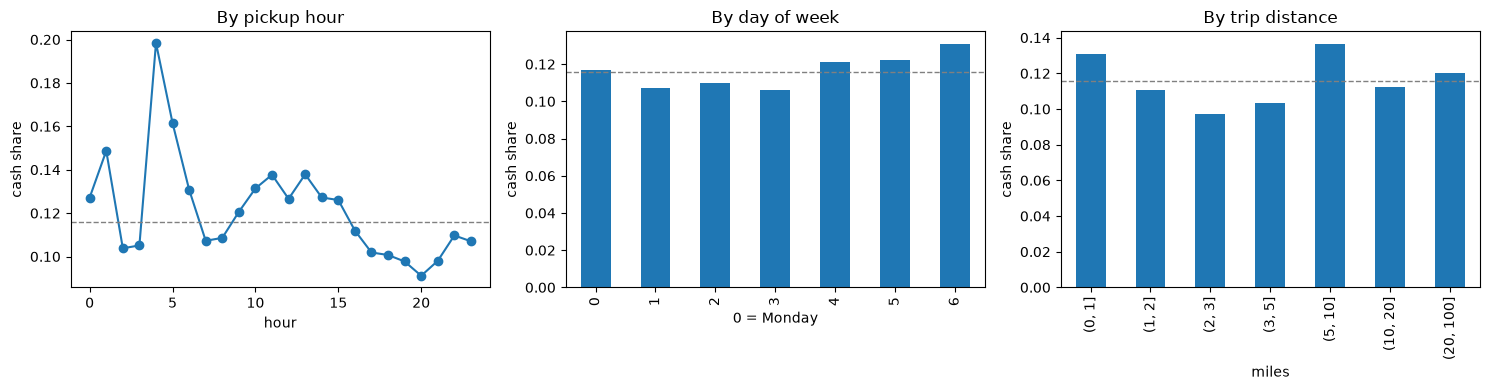

            cash share when 0  cash share when 1
is_weekend              0.112              0.125
is_night                0.115              0.119
has_tolls               0.118              0.091
is_airport              0.110              0.170
same_zone               0.113              0.177

70 pickup zones with 30+ trips; cash share ranges from 0.000 to 0.303


In [14]:
#Cash share for each value of a feature (train only)
def cash_share_by(table, column):
    return table.groupby(column, observed=True)[LABEL].mean()

overall = feat_train[LABEL].mean()
distance_bins = pd.cut(feat_train["trip_distance"], [0, 1, 2, 3, 5, 10, 20, 100])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
cash_share_by(feat_train, "hour").plot(ax=axes[0], marker="o")
axes[0].set(title="By pickup hour", xlabel="hour", ylabel="cash share")
cash_share_by(feat_train, "day_of_week").plot.bar(ax=axes[1])
axes[1].set(title="By day of week", xlabel="0 = Monday", ylabel="cash share")
feat_train.groupby(distance_bins, observed=True)[LABEL].mean().plot.bar(ax=axes[2])
axes[2].set(title="By trip distance", xlabel="miles", ylabel="cash share")
for ax in axes:
    ax.axhline(overall, color="grey", linestyle="--", linewidth=1)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "02_cash_by_feature.png", dpi=120)
plt.show()

#Flags (0 or 1): cash share when the flag is off and on
flags = ["is_weekend", "is_night", "has_tolls", "is_airport", "same_zone"]
print(pd.DataFrame({f: cash_share_by(feat_train, f) for f in flags}).T
        .rename(columns={0: "cash share when 0", 1: "cash share when 1"}).round(3).to_string())

#Pickup zones with the highest and lowest cash share (only zones with enough train trips)
MIN_ZONE_TRIPS = 200 if ON_ROCKHILL else 30
zones = (feat_train.groupby("PULocationID")[LABEL].agg(trips="size", cash_share="mean")
                   .query("trips >= @MIN_ZONE_TRIPS").sort_values("cash_share"))
zones.to_csv(RESULTS_DIR / "02_cash_by_zone.csv")
if len(zones):
    print(f"\n{len(zones)} pickup zones with {MIN_ZONE_TRIPS}+ trips; cash share ranges from "
          f"{zones['cash_share'].min():.3f} to {zones['cash_share'].max():.3f}")

### 2.3 Preprocessing
The models need every column as a number, on a similar scale:

| Columns | What is done | Why |
|---|---|---|
| numeric | scaled to mean 0, standard deviation 1 | logistic regression needs similar scales; trees don't mind |
| `VendorID`, `RatecodeID`, `day_of_week` | one-hot: one 0/1 column per value | few values, no order between them |
| zones and `route` | target encoding: replaced by the cash share of that value in train, shrunk towards the overall share when it has few trips | about 260 zones and tens of thousands of routes, too many for one-hot |

Target encoding uses the label, so it must be fitted on train only. `make_preprocessor()` returns a new, unfitted step that goes inside each model's pipeline in Section 3, so it is fitted on the training data at the same time as the model. scikit-learn's `TargetEncoder` also splits the training data into 5 parts while fitting, so a trip's own label is never used to encode that trip.

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
import sklearn


#TargetEncoder with a fixed seed. scikit-learn 1.9 moved the seed into the cv argument
def make_target_encoder():
    version = tuple(int(part) for part in sklearn.__version__.split(".")[:2])
    if version >= (1, 9):
        return TargetEncoder(target_type="binary",
                             cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
    return TargetEncoder(target_type="binary", random_state=SEED)


#A new, unfitted preprocessing step. It is fitted inside each model's pipeline, on train only
def make_preprocessor():
    return ColumnTransformer([
        ("numeric", StandardScaler(), NUMERIC),
        ("one_hot", OneHotEncoder(handle_unknown="ignore", min_frequency=50), ONE_HOT),
        ("target", make_target_encoder(), TARGET_ENCODED),
    ])


#Quick check on a small part of train: the step runs and gives one row per trip
check = feat_train.sample(n=min(5000, len(feat_train)), random_state=SEED)
encoded = make_preprocessor().fit_transform(check[FEATURES], check[LABEL])
print(f"{len(FEATURES)} features become {encoded.shape[1]} columns after preprocessing")

24 features become 34 columns after preprocessing


## Section 3 · Models

Trains a baseline, then searches over several models and settings. Every model is trained on train and scored on val; test is not used.

Each candidate (one model with one group of settings) is trained and scored on its own, so the candidates are independent tasks. They are run first one after another, then up to `MAX_WORKERS` at the same time in separate worker processes, and the two times are compared. This is the **task parallelism** for the project, alongside the data parallelism of Section 1.

Saves: `results/03_baselines.csv`, `results/03_model_search.csv`, `results/03_timings.json`, `results/03_val_pr_curves.png`, `results/03_final_model.json`, `results/03_feature_importance.csv`, `results/models/final_model.joblib`

### 3.1 How models are scored
Cash is the minority class, so each model is scored on how well it finds **cash** trips:

| Score | Meaning |
|---|---|
| precision | of the trips predicted cash, the share that really were cash |
| recall | of the real cash trips, the share the model found |
| F1 | one number that balances precision and recall |
| PR-AUC | area under the precision-recall curve: how good the model is over every threshold, not just 0.5. A model that guesses scores about the cash share |

Models are ranked by **PR-AUC on val**. It doesn't depend on a threshold, which is chosen afterwards for the final model only (3.5).

In [16]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, f1_score, precision_recall_curve,
                             precision_score, recall_score)
from sklearn.pipeline import Pipeline
import joblib

MODELS_DIR = RESULTS_DIR / "models"
MODELS_DIR.mkdir(exist_ok=True)


#Scores for the cash class. prob is the predicted chance that each trip is cash
def cash_scores(y, prob, threshold=0.5):
    predicted = (prob >= threshold).astype(int)
    return {"precision": precision_score(y, predicted, zero_division=0),
            "recall": recall_score(y, predicted, zero_division=0),
            "f1": f1_score(y, predicted, zero_division=0),
            "pr_auc": average_precision_score(y, prob)}


feat_val = feature_tables["val"]
X_train, y_train = feat_train[FEATURES], feat_train[LABEL]
X_val, y_val = feat_val[FEATURES], feat_val[LABEL]
print(f"train {len(X_train):,} trips, val {len(X_val):,} trips, val cash share {y_val.mean():.3f}")

train 49,406 trips, val 44,888 trips, val cash share 0.114


### 3.2 Baselines
Any real model has to beat these:
* **Always card**: predicts the majority class every time. Its accuracy looks high, but it finds no cash trips.
* **Fare and distance only**: logistic regression on just `fare_amount` and `trip_distance`, to see how much the other features add.

In [17]:
baselines = {}

always_card = DummyClassifier(strategy="prior").fit(X_train, y_train)
prob = always_card.predict_proba(X_val)[:, 1]
baselines["always card"] = {**cash_scores(y_val, prob),
                            "accuracy": ((prob >= 0.5) == y_val).mean()}

simple_columns = ["fare_amount", "trip_distance"]
simple = Pipeline([("scale", StandardScaler()),
                   ("model", LogisticRegression(class_weight="balanced", max_iter=1000))])
simple.fit(X_train[simple_columns], y_train)
prob = simple.predict_proba(X_val[simple_columns])[:, 1]
baselines["fare and distance only"] = {**cash_scores(y_val, prob),
                                       "accuracy": ((prob >= 0.5) == y_val).mean()}

baselines = pd.DataFrame(baselines).T.round(4)
baselines.to_csv(RESULTS_DIR / "03_baselines.csv")
baselines

,precision,recall,f1,pr_auc,accuracy
always card,0.0000,0.0000,0.0000,0.1141,0.8859
fare and distance only,0.1091,0.5534,0.1823,0.1115,0.4334


### 3.3 Model search: one model or several at once
Three kinds of model, each with a few settings:

| Model | Settings tried | Notes |
|---|---|---|
| logistic regression | `C` (how strongly the weights are held back): 0.1, 1, 10 | fast; a straight-line boundary |
| histogram gradient boosting | learning rate 0.05 or 0.1, 31 or 63 leaves per tree | usually the strongest on tables like this |
| random forest | 8 or 16 levels deep | each tree sees 20% of train, to keep it fast on Rockhill |

`class_weight="balanced"` makes a missed cash trip count as much as all the extra card trips, so the models don't just predict card. Two boosting candidates are trained without it to compare.

`fit_and_score` trains and scores one candidate. Each worker reads the feature files from `prepared/` itself, like `prepare_month` does in Section 1, so the training data isn't copied to every worker.

In [18]:
CANDIDATES = (
    [("logistic regression", {"C": c, "class_weight": "balanced"}) for c in (0.1, 1, 10)]
    + [("gradient boosting", {"learning_rate": lr, "max_leaf_nodes": leaves, "class_weight": "balanced"})
       for lr in (0.05, 0.1) for leaves in (31, 63)]
    + [("gradient boosting", {"learning_rate": 0.1, "max_leaf_nodes": leaves, "class_weight": None})
       for leaves in (31, 63)]
    + [("random forest", {"max_depth": depth, "class_weight": "balanced"}) for depth in (8, 16)]
)


#Builds an unfitted pipeline (preprocessing + model) for one candidate
def make_model(kind, params, seed=SEED):
    if kind == "logistic regression":
        model = LogisticRegression(max_iter=2000, **params)
    elif kind == "gradient boosting":
        model = HistGradientBoostingClassifier(max_iter=300, early_stopping=True,
                                               random_state=seed, **params)
    elif kind == "random forest":
        model = RandomForestClassifier(n_estimators=100, max_samples=0.2, min_samples_leaf=20,
                                       n_jobs=1, random_state=seed, **params)
    else:
        raise ValueError(f"unknown model {kind}")
    return Pipeline([("prep", make_preprocessor()), ("model", model)])


#Trains one candidate on train and scores it on val. Runs in a worker process
def fit_and_score(kind, params, features, label, data_dir, seed):
    start = time.perf_counter()
    train = pd.read_parquet(Path(data_dir) / "features_train.parquet")
    val = pd.read_parquet(Path(data_dir) / "features_val.parquet")
    pipe = make_model(kind, params, seed).fit(train[features], train[label])
    prob = pipe.predict_proba(val[features])[:, 1]
    return {"model": kind, "params": json.dumps(params), **cash_scores(val[label], prob),
            "seconds": round(time.perf_counter() - start, 2)}


#Trains every candidate using n workers
def search(n_workers):
    jobs = [delayed(fit_and_score)(kind, params, FEATURES, LABEL, PREPARED_DIR, SEED)
            for kind, params in CANDIDATES]
    return pd.DataFrame(Parallel(n_jobs=n_workers)(jobs))


RUN_SEQUENTIAL_SEARCH = True
search_timings = {"candidates": len(CANDIDATES), "workers": min(MAX_WORKERS, len(CANDIDATES)),
                  "train_trips": len(X_train)}
if RUN_SEQUENTIAL_SEARCH:
    start = time.perf_counter()
    search(n_workers=1)
    search_timings["sequential_s"] = round(time.perf_counter() - start, 2)

start = time.perf_counter()
results = search(n_workers=search_timings["workers"])
search_timings["parallel_s"] = round(time.perf_counter() - start, 2)
if RUN_SEQUENTIAL_SEARCH:
    search_timings["speedup"] = round(search_timings["sequential_s"] / search_timings["parallel_s"], 2)

pd.set_option("display.max_colwidth", 90)
results = results.sort_values("pr_auc", ascending=False).reset_index(drop=True)
results.to_csv(RESULTS_DIR / "03_model_search.csv", index=False)
(RESULTS_DIR / "03_timings.json").write_text(json.dumps(search_timings, indent=2))
print(search_timings)
results.round(4)

{'candidates': 11, 'workers': 3, 'train_trips': 49406, 'sequential_s': 23.31, 'parallel_s': 10.36, 'speedup': 2.25}


,model,params,precision,recall,f1,pr_auc,seconds
0,gradient boosting,"{""learning_rate"": 0.05, ""max_leaf_nodes"": 31, ""class_weight"": ""balanced""}",0.1731,0.5278,0.2607,0.2577,4.07
1,gradient boosting,"{""learning_rate"": 0.1, ""max_leaf_nodes"": 31, ""class_weight"": null}",0.7311,0.0472,0.0887,0.2572,1.38
2,gradient boosting,"{""learning_rate"": 0.1, ""max_leaf_nodes"": 31, ""class_weight"": ""balanced""}",0.1731,0.5216,0.2599,0.2571,2.95
3,gradient boosting,"{""learning_rate"": 0.05, ""max_leaf_nodes"": 63, ""class_weight"": ""balanced""}",0.1779,0.5009,0.2625,0.2552,3.96
4,random forest,"{""max_depth"": 8, ""class_weight"": ""balanced""}",0.1719,0.5567,0.2627,0.2551,1.93
5,gradient boosting,"{""learning_rate"": 0.1, ""max_leaf_nodes"": 63, ""class_weight"": ""balanced""}",0.1737,0.5038,0.2584,0.2544,2.80
6,gradient boosting,"{""learning_rate"": 0.1, ""max_leaf_nodes"": 63, ""class_weight"": null}",0.7083,0.0498,0.0930,0.2543,1.46
7,random forest,"{""max_depth"": 16, ""class_weight"": ""balanced""}",0.1752,0.5479,0.2655,0.2533,2.53
8,logistic regression,"{""C"": 10, ""class_weight"": ""balanced""}",0.1701,0.5495,0.2598,0.2481,0.73
9,logistic regression,"{""C"": 1, ""class_weight"": ""balanced""}",0.1692,0.5466,0.2584,0.2475,0.79


### 3.4 Comparing the models on val
The best candidate of each kind, as precision-recall curves on val. A curve further up and to the right is better. The dashed line is the cash share, which is what guessing would give.

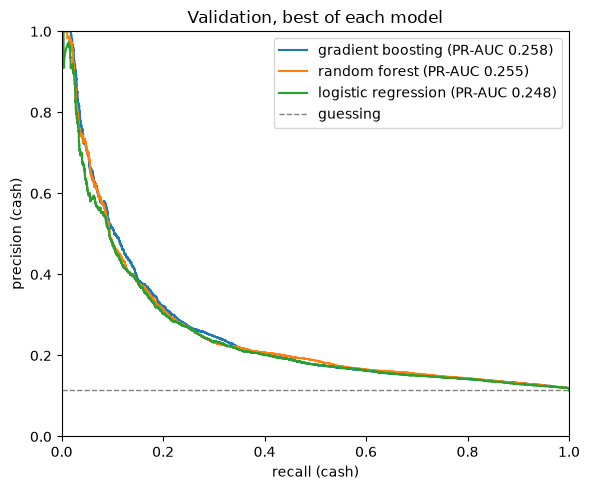

In [19]:
best_per_kind = results.drop_duplicates("model")
fig, ax = plt.subplots(figsize=(6, 5))
val_probs = {}
for _, row in best_per_kind.iterrows():
    pipe = make_model(row["model"], json.loads(row["params"])).fit(X_train, y_train)
    val_probs[row["model"]] = (pipe, json.loads(row["params"]), pipe.predict_proba(X_val)[:, 1])
    precision, recall, _ = precision_recall_curve(y_val, val_probs[row["model"]][2])
    ax.plot(recall, precision, label=f"{row['model']} (PR-AUC {row['pr_auc']:.3f})")
ax.axhline(y_val.mean(), color="grey", linestyle="--", linewidth=1, label="guessing")
ax.set(xlabel="recall (cash)", ylabel="precision (cash)", title="Validation, best of each model",
       xlim=(0, 1), ylim=(0, 1))
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "03_val_pr_curves.png", dpi=120)
plt.show()

### 3.5 Final model
The candidate with the highest PR-AUC on val is the final model. It stays trained on train only, so val is still unseen data for choosing its **threshold**: the predicted chance of cash above which a trip is called cash. The threshold with the best F1 on val is used.

Section 4 loads the model and threshold like this:
```python
final = joblib.load(RESULTS_DIR / "models" / "final_model.joblib")
X_test = add_features(load_split("test"))[FEATURES]
prob = final["pipeline"].predict_proba(X_test)[:, 1]
predicted_cash = prob >= final["threshold"]
```

In [20]:
best = results.iloc[0]
final_pipe, final_params, prob = val_probs[best["model"]]

#The threshold with the best F1 on val (the last precision/recall pair has no threshold)
precision, recall, thresholds = precision_recall_curve(y_val, prob)
f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
THRESHOLD = float(thresholds[np.argmax(f1[:-1])])

final_info = {"model": best["model"], "params": final_params, "threshold": round(THRESHOLD, 4),
              "features": FEATURES, "trained_on": TRAIN, "threshold_chosen_on": VAL,
              "val_at_0.5": {k: round(v, 4) for k, v in cash_scores(y_val, prob, 0.5).items()},
              "val_at_threshold": {k: round(v, 4) for k, v in cash_scores(y_val, prob, THRESHOLD).items()}}
joblib.dump({"pipeline": final_pipe, "threshold": THRESHOLD, "features": FEATURES},
            MODELS_DIR / "final_model.joblib")
(RESULTS_DIR / "03_final_model.json").write_text(json.dumps(final_info, indent=2))

print(f"Final model: {best['model']} {final_params}")
print(f"Threshold: {THRESHOLD:.3f}")
print(pd.DataFrame({"at 0.5": final_info["val_at_0.5"],
                    f"at {THRESHOLD:.3f}": final_info["val_at_threshold"]}).T.to_string())

Final model: gradient boosting {'learning_rate': 0.05, 'max_leaf_nodes': 31, 'class_weight': 'balanced'}
Threshold: 0.573
          precision  recall      f1  pr_auc
at 0.5       0.1731  0.5278  0.2607  0.2577
at 0.573     0.2377  0.3223  0.2736  0.2577


### 3.6 Which features the final model relies on
Permutation importance on val: shuffle one feature at a time and see how far PR-AUC drops. A big drop means the model leans on that feature. Uses up to 20,000 val trips to keep it quick.

In [21]:
from sklearn.inspection import permutation_importance

part = feat_val.sample(n=min(20_000, len(feat_val)), random_state=SEED)
importance = permutation_importance(final_pipe, part[FEATURES], part[LABEL],
                                    scoring="average_precision", n_repeats=3,
                                    random_state=SEED, n_jobs=1)
importance = (pd.DataFrame({"feature": FEATURES, "pr_auc_drop": importance.importances_mean})
                .sort_values("pr_auc_drop", ascending=False).reset_index(drop=True))
importance.to_csv(RESULTS_DIR / "03_feature_importance.csv", index=False)
importance.head(10).round(4)

,feature,pr_auc_drop
0,RatecodeID,0.0469
1,DOLocationID,0.0430
2,congestion_surcharge,0.0392
3,PULocationID,0.0239
4,fare_per_mile,0.0114
5,speed_mph,0.0112
6,fare_amount,0.0076
7,duration_min,0.0054
8,hour,0.0049
9,trip_distance,0.0043


## Section 4 · Evaluation

Score the Section 3 models on the held-out test months. Cash is 1 and card is 0. The final model and its decision threshold were chosen using validation data.

Saves: `results/04_test_scores.csv`, `results/04_confusion_matrix.png`

### 4.1 Predict on the test trips

Apply the same feature preparation used for training. Use the feature order and full-precision threshold saved with the fitted pipeline.

In [22]:
final = joblib.load(MODELS_DIR / "final_model.joblib")
feat_test = add_features(load_split("test"))
X_test = feat_test[final["features"]]
y_test = feat_test[LABEL]

cash_prob = final["pipeline"].predict_proba(X_test)[:, 1]
threshold = final["threshold"]
predicted_cash = (cash_prob >= threshold).astype(int)

print("Test months:", ", ".join(TEST))
print(f"{len(y_test):,} trips, {y_test.mean():.1%} cash, threshold {threshold:.4f}")

C:\Users\franc\AppData\Local\Temp\ipykernel_16804\2287074843.py:12: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  out["day_of_week"] = pickup.dt.dayofweek.astype("int8")


Test months: 2026-03
57,229 trips, 11.5% cash, threshold 0.5729


### 4.2 Compare with the baselines

Use the same scoring rules as Section 3. Precision measures how often a cash prediction is correct. Recall measures how many actual cash trips we find. F1 balances the two. The `pr_auc` column uses average precision across thresholds. For the constant baseline, average precision equals the test cash share.

In [23]:
# Each row uses the same test trips and the decision threshold set before testing
test_models = [
    ("always card", always_card.predict_proba(X_test)[:, 1], 0.5),
    ("fare and distance only", simple.predict_proba(X_test[simple_columns])[:, 1], 0.5),
    (best["model"], cash_prob, threshold),
]

rows = []
for name, probabilities, cutoff in test_models:
    scores = cash_scores(y_test, probabilities, cutoff)
    rows.append({"model": name, "threshold": cutoff,
                 "accuracy": ((probabilities >= cutoff) == y_test).mean(), **scores})

test_scores = pd.DataFrame(rows).set_index("model")
test_scores.to_csv(RESULTS_DIR / "04_test_scores.csv")
test_scores.round(4)

,threshold,accuracy,precision,recall,f1,pr_auc
model,,,,,,
always card,0.5000,0.8846,0.0000,0.0000,0.0000,0.1154
fare and distance only,0.5000,0.4701,0.1114,0.5153,0.1833,0.1132
gradient boosting,0.5729,0.8009,0.2308,0.3110,0.2649,0.2551


### 4.3 Which payments did the final model get wrong?

Rows show the actual payment and columns show the prediction. The bottom-left cell counts cash trips predicted as card. The top-right cell counts card trips predicted as cash.

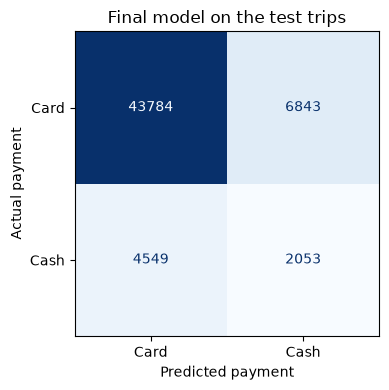

In [24]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, predicted_cash, labels=[0, 1], display_labels=["Card", "Cash"],
    cmap="Blues", colorbar=False, values_format="d", ax=ax
)
ax.set(title="Final model on the test trips", xlabel="Predicted payment", ylabel="Actual payment")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "04_confusion_matrix.png", dpi=120)
plt.show()